# Exploratory Data Analysis — Concrete Compressive Strength

## Mục tiêu
Khám phá dữ liệu thành phần cấp phối và tuổi bê tông để hiểu các đặc điểm liên quan đến cường độ chịu nén.

## Bài toán
Đây là bài toán hồi quy. Biến mục tiêu là cường độ chịu nén của bê tông, được đo bằng MPa.

## Phạm vi EDA
Kiểm tra cấu trúc và chất lượng dữ liệu; khảo sát phân phối của target và các đặc trưng; phân tích mối liên hệ giữa từng đặc trưng với cường độ chịu nén; và tạo một số chỉ số cấp phối để khảo sát thêm.

## Lưu ý
Các mối liên hệ quan sát được trong EDA không chứng minh quan hệ nhân quả. Các tỷ lệ cấp phối tạo ra để khảo sát chỉ là biến dẫn xuất, cần được đánh giá riêng khi xây dựng mô hình.

Data Loading

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/raw/Concrete_Data.xls")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file: {DATA_PATH.resolve()}")

df = pd.read_excel(DATA_PATH, header=0)

def normalize_column_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

expected_names = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
    "concrete_compressive_strength",
]

def standardize_column_name(name):
    normalized = normalize_column_name(name)

    for expected in sorted(expected_names, key=len, reverse=True):
        if normalized == expected or normalized.startswith(expected + "_"):
            return expected

    return normalized

df.columns = [standardize_column_name(col) for col in df.columns]

TARGET = "concrete_compressive_strength"

print(f"Đã nạp: {DATA_PATH.name}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]:,} cột")
print("Tên cột sau chuẩn hóa:", df.columns.tolist())

if TARGET not in df.columns:
    raise KeyError(
        f"Không tìm thấy target {TARGET!r}. "
        f"Hãy kiểm tra danh sách tên cột ở trên."
    )

Đã nạp: Concrete_Data.xls
Kích thước: 1,030 dòng × 9 cột
Tên cột sau chuẩn hóa: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'concrete_compressive_strength']


Dataset Overview

In [2]:
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))

print("Kích thước:", df.shape)
print("\nKiểu dữ liệu:")
display(df.dtypes.rename("dtype").to_frame())

print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df.describe().T)

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
31,266.0,114.0,0.0,228.0,0.0,932.0,670.0,365,52.908320
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
136,389.9,189.0,0.0,145.9,22.0,944.7,755.8,28,74.497882
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
918,145.0,0.0,179.0,202.0,8.0,824.0,869.0,28,10.535193


Kích thước: (1030, 9)

Kiểu dữ liệu:


,dtype
cement,float64
blast_furnace_slag,float64
fly_ash,float64
water,float64
superplasticizer,float64
coarse_aggregate,float64
fine_aggregate,float64
age,int64
concrete_compressive_strength,float64



Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
blast_furnace_slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
concrete_compressive_strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


Data Quality

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=False),
    "zero_count": (df == 0).sum(),
    "negative_count": (df < 0).sum(),
})

display(quality)

print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số dòng trùng theo đặc trưng:", df.drop(columns=[TARGET]).duplicated().sum())

,dtype,missing_count,missing_pct,n_unique,zero_count,negative_count
cement,float64,0,0.0,280,0,0
blast_furnace_slag,float64,0,0.0,187,466,0
fly_ash,float64,0,0.0,163,566,0
water,float64,0,0.0,205,0,0
superplasticizer,float64,0,0.0,155,379,0
coarse_aggregate,float64,0,0.0,284,0,0
fine_aggregate,float64,0,0.0,304,0,0
age,int64,0,0.0,14,0,0
concrete_compressive_strength,float64,0,0.0,938,0,0


Số dòng trùng hoàn toàn: 25
Số dòng trùng theo đặc trưng: 34


Univariate Analysis

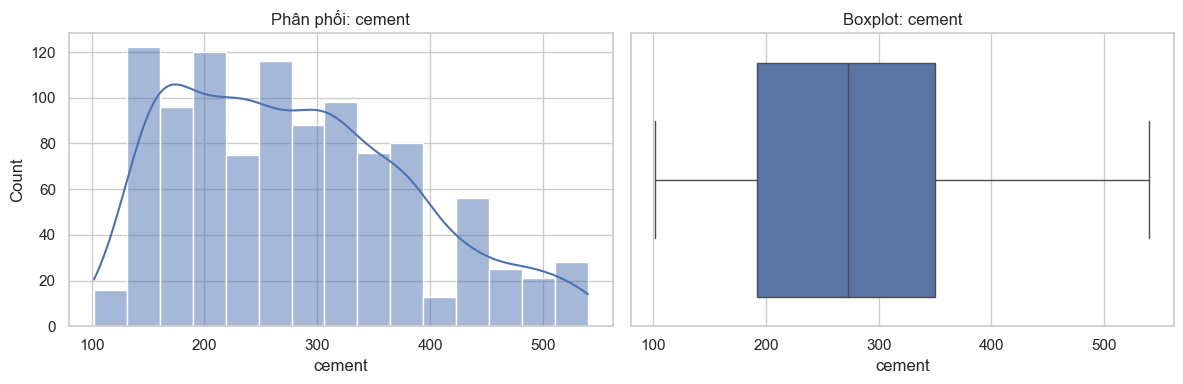

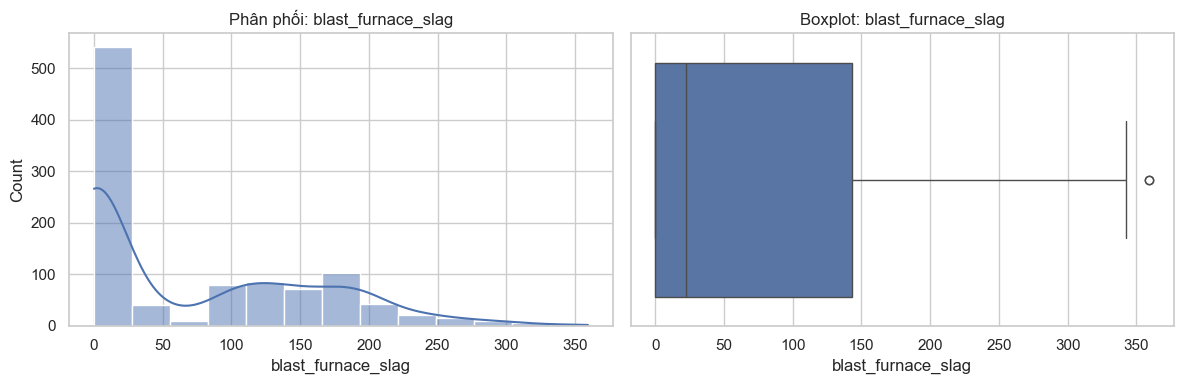

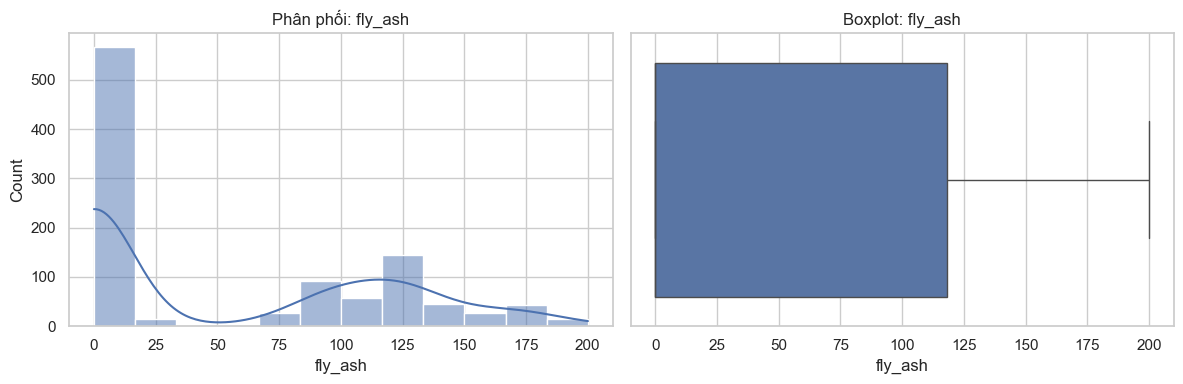

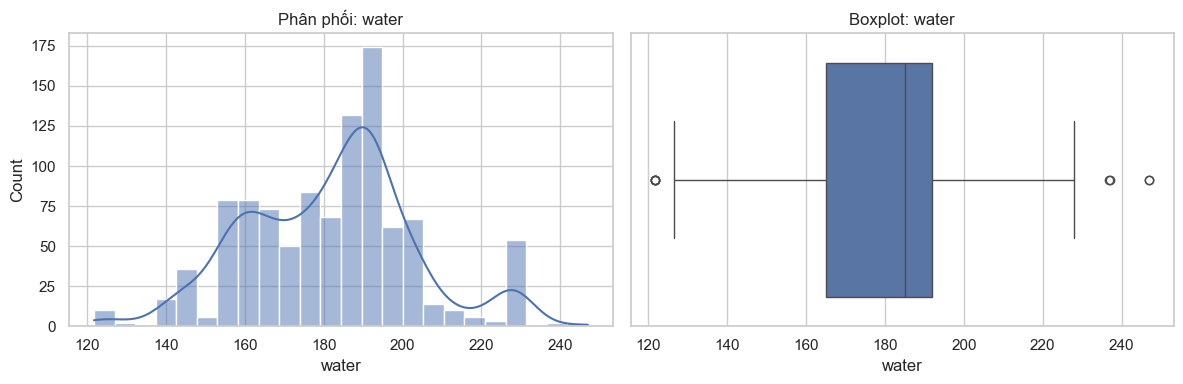

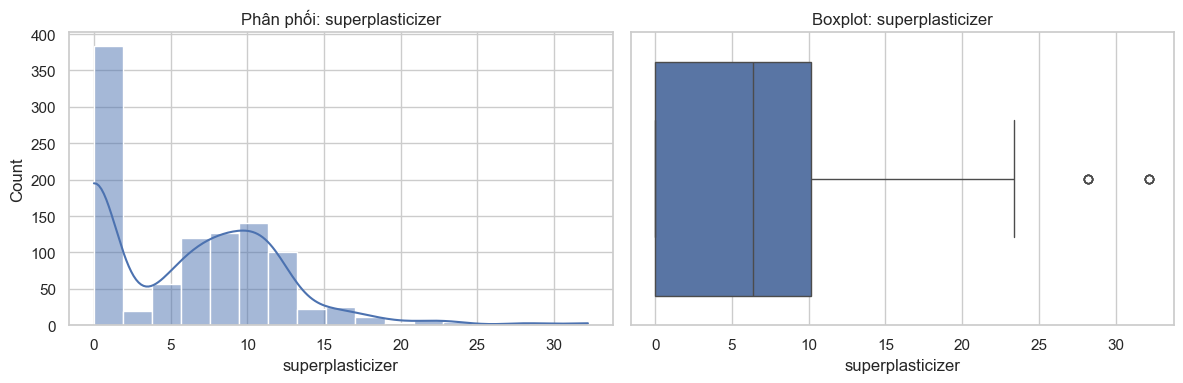

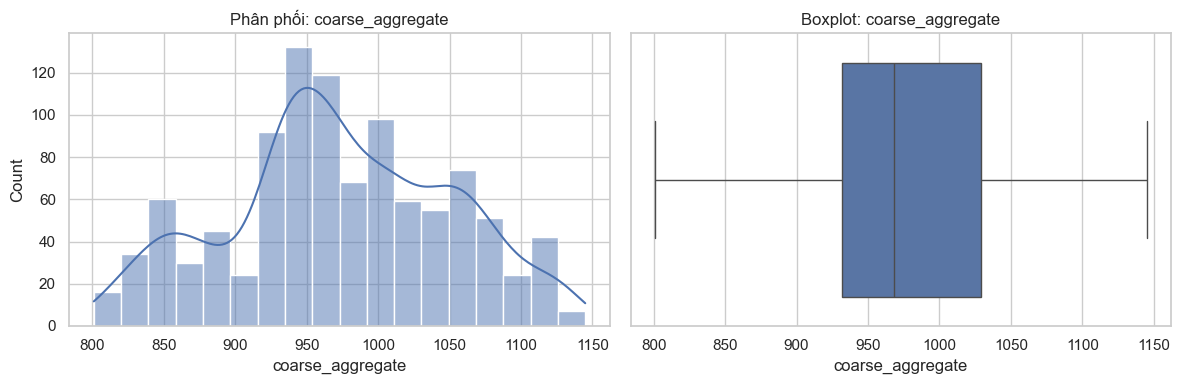

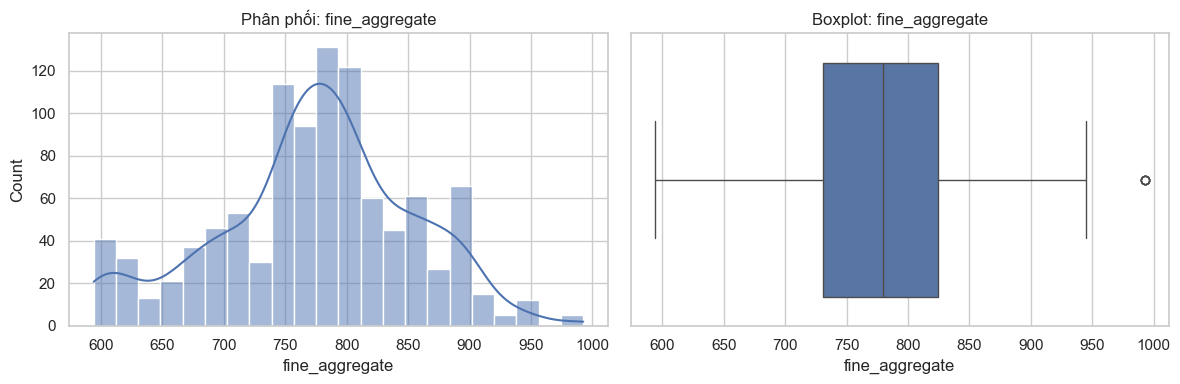

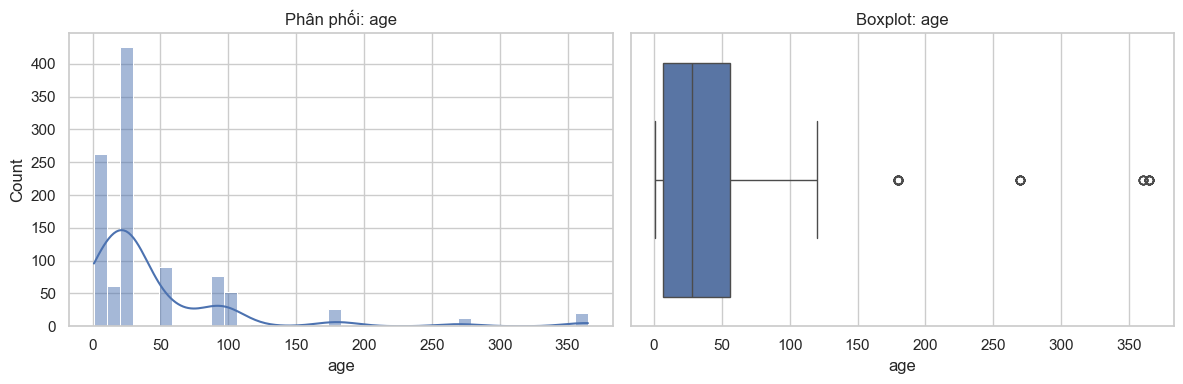

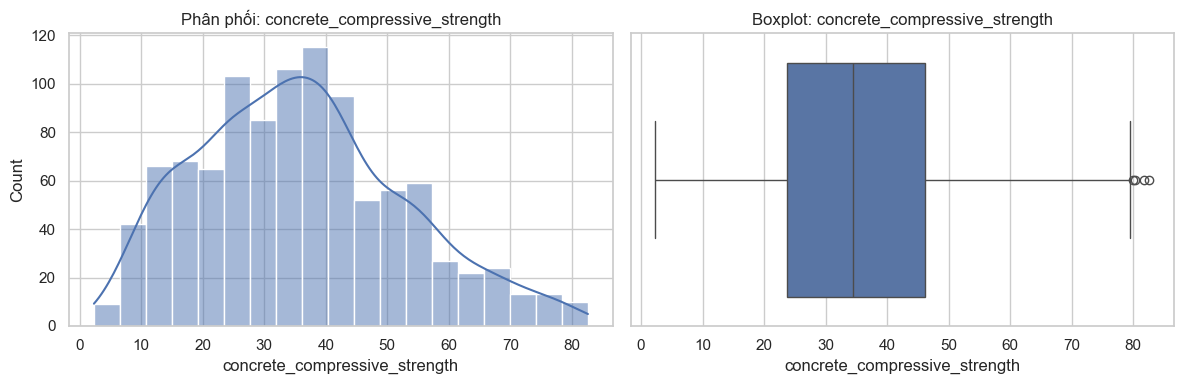

In [4]:
feature_cols = [col for col in df.columns if col != TARGET]

for col in feature_cols + [TARGET]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Phân phối: {col}")

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")

    plt.tight_layout()
    plt.show()

Bivariate Analysis

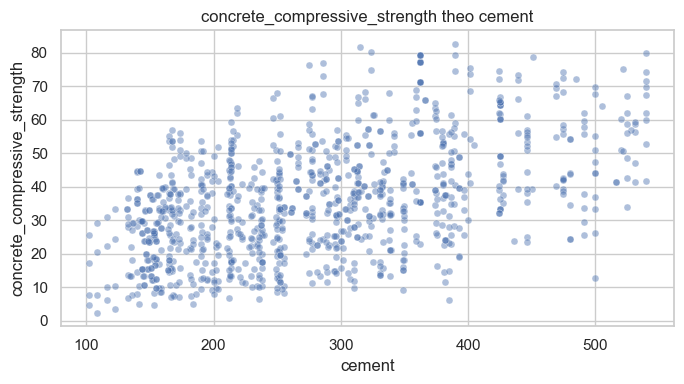

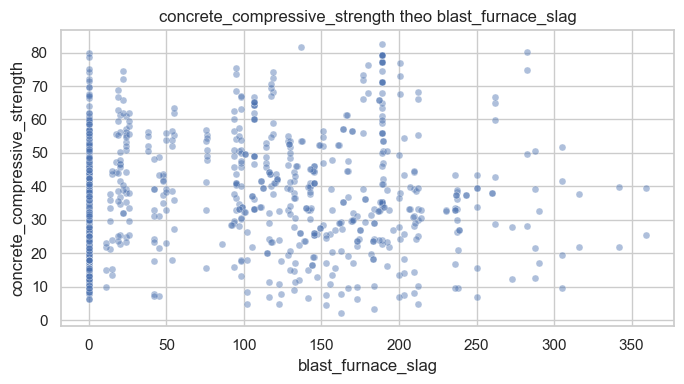

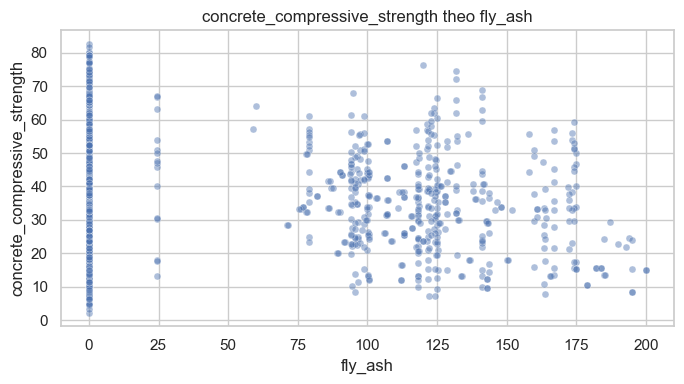

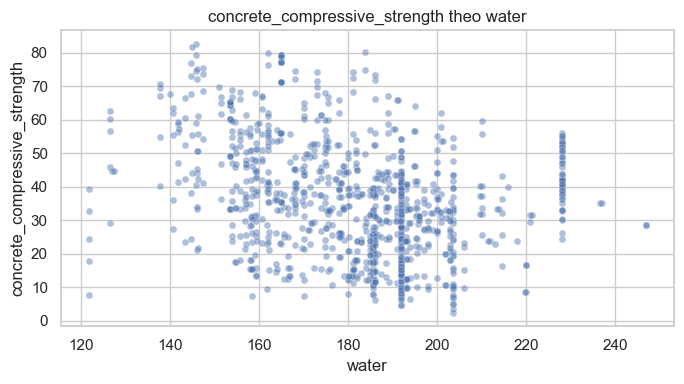

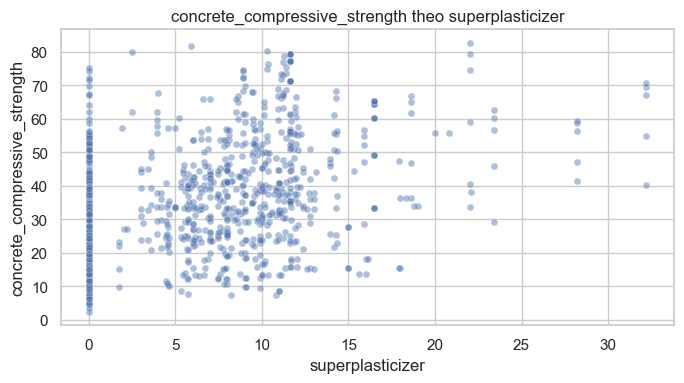

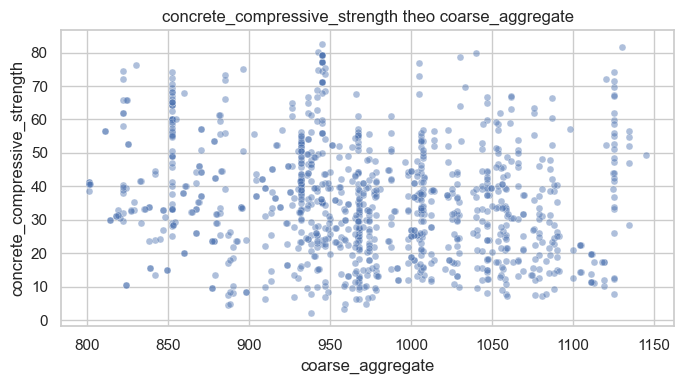

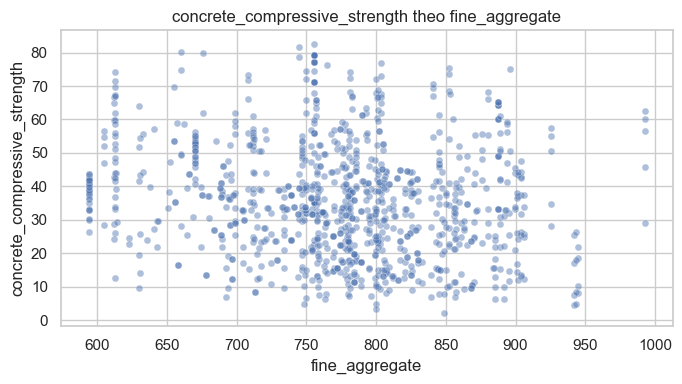

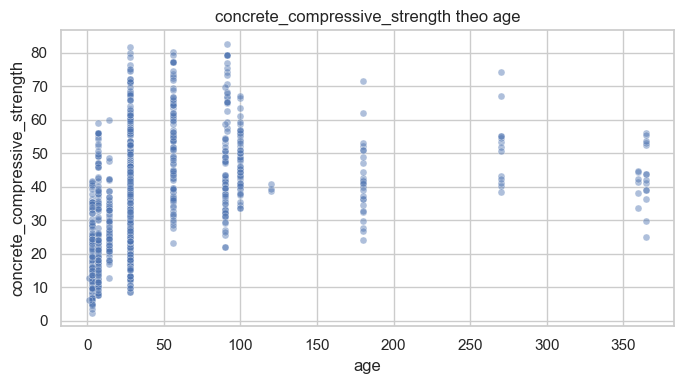

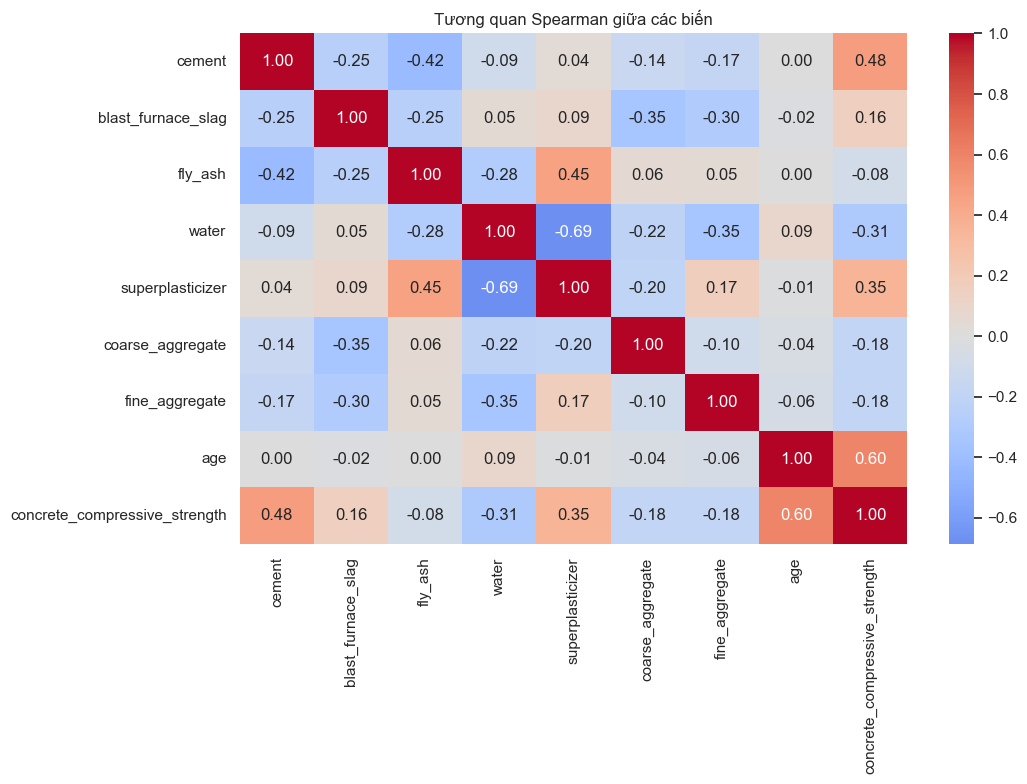

,spearman_corr_with_target
age,0.596020
cement,0.477601
superplasticizer,0.347589
water,-0.308371
coarse_aggregate,-0.183516
fine_aggregate,-0.179991
blast_furnace_slag,0.162473
fly_ash,-0.077957


In [5]:
feature_cols = [col for col in df.columns if col != TARGET]

for col in feature_cols:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(
        data=df,
        x=col,
        y=TARGET,
        alpha=0.45,
        s=25
    )
    plt.title(f"{TARGET} theo {col}")
    plt.tight_layout()
    plt.show()

spearman_corr = df.corr(method="spearman", numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(spearman_corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Tương quan Spearman giữa các biến")
plt.tight_layout()
plt.show()

display(
    spearman_corr[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .rename("spearman_corr_with_target")
    .to_frame()
)

Target Analysis

,value
count,1030.000000
mean,35.817836
std,16.705679
min,2.331808
25%,23.707115
50%,34.442774
75%,46.136287
max,82.599225


Skewness của target: 0.417


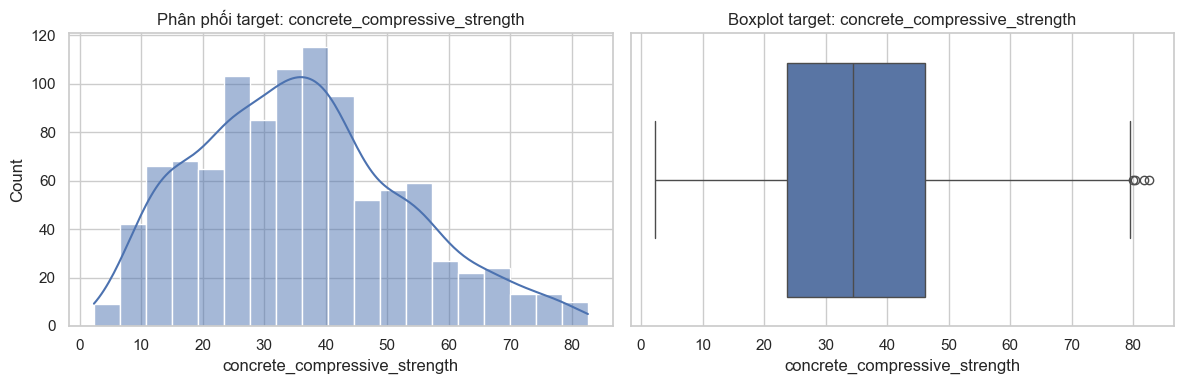

Các phân vị của target:


,value
0.00,2.331808
0.01,6.889127
0.25,23.707115
0.50,34.442774
0.75,46.136287
0.99,77.297154
1.00,82.599225


In [6]:
target_series = df[TARGET]

display(target_series.describe().to_frame("value"))
print(f"Skewness của target: {target_series.skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(target_series.dropna(), kde=True, ax=axes[0])
axes[0].set_title(f"Phân phối target: {TARGET}")

sns.boxplot(x=target_series, ax=axes[1])
axes[1].set_title(f"Boxplot target: {TARGET}")

plt.tight_layout()
plt.show()

print("Các phân vị của target:")
display(target_series.quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 1]).to_frame("value"))

Domain-specific EDA

,count,mean,std,min,25%,50%,75%,max
binder_total,1030.0,409.248252,92.783290,200.000000,336.380000,391.350000,483.700000,640.000000
water_binder_ratio,1030.0,0.469236,0.127127,0.235073,0.383916,0.472118,0.561244,0.900000
aggregate_total,1030.0,1746.497476,101.233221,1457.000000,1679.000000,1752.900000,1827.945000,1970.000000
concrete_compressive_strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225
age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000


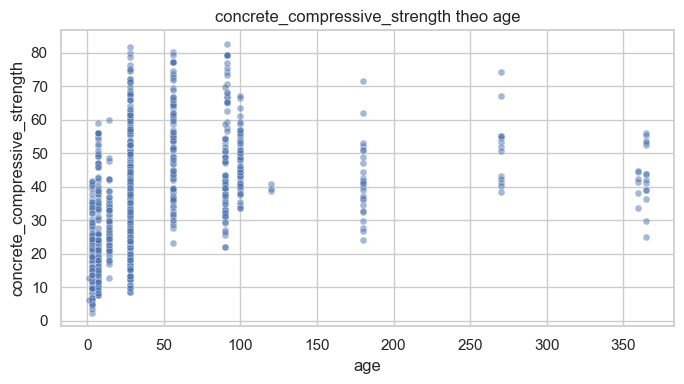

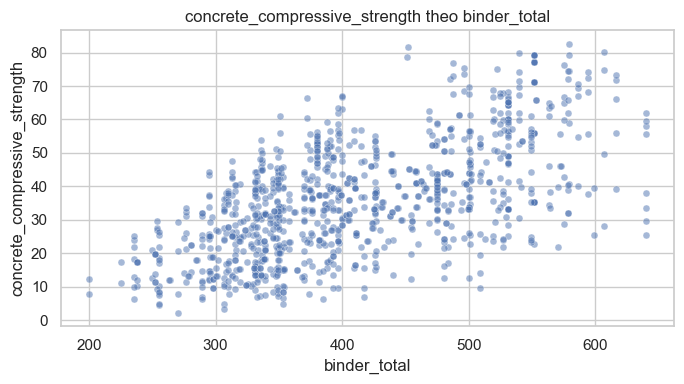

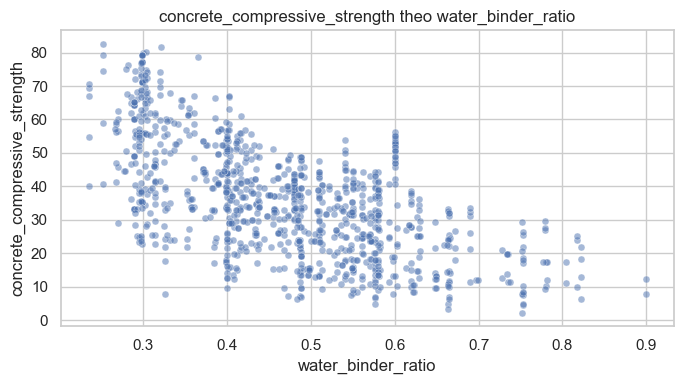

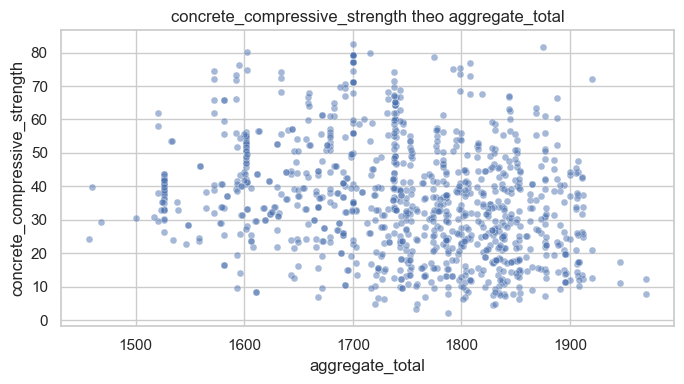

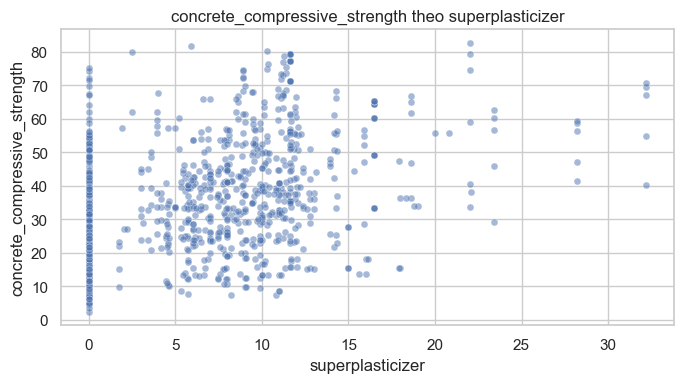

Tương quan Spearman của các chỉ số dẫn xuất với target:


,spearman_corr_with_target
water_binder_ratio,-0.605851
binder_total,0.599410
age,0.596020
superplasticizer,0.347589
aggregate_total,-0.289345


In [7]:
required_for_domain = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
]

missing_domain_cols = [
    col for col in required_for_domain
    if col not in df.columns
]

if missing_domain_cols:
    print("Thiếu cột cho phân tích cấp phối:", missing_domain_cols)
else:
    domain = pd.DataFrame(index=df.index)

    domain["binder_total"] = (
        df["cement"]
        + df["blast_furnace_slag"]
        + df["fly_ash"]
    )

    domain["water_binder_ratio"] = (
        df["water"]
        / domain["binder_total"].replace(0, np.nan)
    )

    domain["aggregate_total"] = (
        df["coarse_aggregate"]
        + df["fine_aggregate"]
    )

    domain[TARGET] = df[TARGET]
    domain["age"] = df["age"]
    domain["superplasticizer"] = df["superplasticizer"]

    display(domain.describe().T)

    domain_plot_cols = [
        "age",
        "binder_total",
        "water_binder_ratio",
        "aggregate_total",
        "superplasticizer",
    ]

    for col in domain_plot_cols:
        plt.figure(figsize=(7, 4))
        sns.scatterplot(
            data=domain,
            x=col,
            y=TARGET,
            alpha=0.5,
            s=25
        )
        plt.title(f"{TARGET} theo {col}")
        plt.tight_layout()
        plt.show()

    print("Tương quan Spearman của các chỉ số dẫn xuất với target:")
    display(
        domain.corr(method="spearman", numeric_only=True)[TARGET]
        .drop(TARGET)
        .sort_values(key=lambda values: values.abs(), ascending=False)
        .rename("spearman_corr_with_target")
        .to_frame()
    )

In [8]:
feature_cols = [col for col in df.columns if col != TARGET]

duplicate_compositions = (
    df.groupby(feature_cols, dropna=False)
    .agg(
        n_rows=(TARGET, "size"),
        n_target_values=(TARGET, "nunique"),
        target_min=(TARGET, "min"),
        target_max=(TARGET, "max"),
    )
    .query("n_rows > 1")
    .sort_values(["n_target_values", "n_rows"], ascending=False)
)

display(duplicate_compositions)

print(
    "Số cấp phối lặp có nhiều giá trị target:",
    int((duplicate_compositions["n_target_values"] > 1).sum())
)

n_rows  \
cement blast_furnace_slag fly_ash water superplasticizer coarse_aggregate fine_aggregate age           
362.6  189.0              0.0     164.9 11.60            944.7            755.8          7         4   
359.0  19.0               141.0   154.0 10.91            942.0            801.0          3         2   
                                                                                         7         2   
                                                                                         28        2   
                                                                                         56        2   
446.0  24.0               79.0    162.0 11.64            967.0            712.0          3         2   
                                                                                         7         2   
                                                                                         28        2   
                                                                                         56        2   
362.6  189.0              0.0     164.9 11.60            944.7            755.8          3         4   
                                                                                         28        4   
                                                                                         56        4   
                                                                                         91        4   
425.0  106.3              0.0     153.5 16.50            852.1            887.1          3         3   
                                                                                         7         3   
                                                                                         28        3   
                                                                                         56        3   
                                                                                         91        3   
252.0  0.0                0.0     185.0 0.00             1111.0           784.0          28        2   

                                                                                              n_target_values  \
cement blast_furnace_slag fly_ash water superplasticizer coarse_aggregate fine_aggregate age                    
362.6  189.0              0.0     164.9 11.60            944.7            755.8          7                  2   
359.0  19.0               141.0   154.0 10.91            942.0            801.0          3                  2   
                                                                                         7                  2   
                                                                                         28                 2   
                                                                                         56                 2   
446.0  24.0               79.0    162.0 11.64            967.0            712.0          3                  2   
                                                                                         7                  2   
                                                                                         28                 2   
                                                                                         56                 2   
362.6  189.0              0.0     164.9 11.60            944.7            755.8          3                  1   
                                                                                         28                 1   
                                                                                         56                 1   
                                                                                         91                 1   
425.0  106.3              0.0     153.5 16.50            852.1            887.1          3                  1   
                                                                                         7           

Số cấp phối lặp có nhiều giá trị target: 9


In [9]:
feature_cols = [col for col in df.columns if col != TARGET]

has_multiple_targets = (
    df.groupby(feature_cols, dropna=False)[TARGET]
    .transform("nunique")
    .gt(1)
)

conflict_rows = (
    df.loc[has_multiple_targets]
    .sort_values(feature_cols + [TARGET])
)

display(conflict_rows)

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
526,359.0,19.0,141.0,154.0,10.91,942.0,801.0,3,23.639177
525,359.0,19.0,141.0,154.0,10.91,942.0,801.0,3,25.116626
527,359.0,19.0,141.0,154.0,10.91,942.0,801.0,7,35.754255
528,359.0,19.0,141.0,154.0,10.91,942.0,801.0,7,38.610656
524,359.0,19.0,141.0,154.0,10.91,942.0,801.0,28,59.494884
523,359.0,19.0,141.0,154.0,10.91,942.0,801.0,28,62.935369
530,359.0,19.0,141.0,154.0,10.91,942.0,801.0,56,66.780675
529,359.0,19.0,141.0,154.0,10.91,942.0,801.0,56,68.750607
114,362.6,189.0,0.0,164.9,11.60,944.7,755.8,7,22.897498
106,362.6,189.0,0.0,164.9,11.60,944.7,755.8,7,55.895819


## EDA Conclusion

- **Quy mô dữ liệu:** Bộ dữ liệu có 1.030 mẫu, 8 đặc trưng định lượng và target `concrete_compressive_strength` tính bằng MPa.
- **Chất lượng dữ liệu:** Không ghi nhận giá trị thiếu hoặc giá trị âm. Có nhiều giá trị 0 ở `blast_furnace_slag`, `fly_ash` và `superplasticizer`; đây có thể là cấp phối không sử dụng thành phần đó, không nên mặc định xem là dữ liệu thiếu.
- **Target:** Cường độ chịu nén trung bình là 35,82 MPa, trung vị 34,44 MPa, độ lệch chuẩn 16,71 MPa và khoảng giá trị từ 2,33 đến 82,60 MPa. Phân phối hơi lệch phải (skewness = 0,417); không nên loại các giá trị cao chỉ dựa trên boxplot.
- **Tuổi bê tông:** `age` có trung vị 28 ngày, trung bình 45,66 ngày và khoảng từ 1 đến 365 ngày. Dữ liệu tập trung ở một số mốc tuổi cụ thể, nên biểu đồ theo tuổi tạo thành các cụm.
- **Mối liên hệ với target:** Tương quan Spearman cao nhất trong các đặc trưng gốc là `age` (0,596), tiếp theo là `cement` (0,478) và `superplasticizer` (0,348). `water` có tương quan âm (-0,308). Các đặc trưng còn lại có tương quan yếu hơn trong phân tích này.
- **Đặc điểm cấp phối dẫn xuất:** `water_binder_ratio` có tương quan Spearman -0,606 và `binder_total` có tương quan 0,599 với target. Đây là các xu hướng quan sát được trong dữ liệu, không chứng minh quan hệ nhân quả.
- **Cấp phối lặp:** Phát hiện 25 dòng trùng hoàn toàn, 34 dòng có bộ đặc trưng đã xuất hiện trước đó và 9 bộ đặc trưng đi kèm nhiều giá trị target. Một nhóm cần kiểm tra với dữ liệu gốc: cấp phối có `cement=362.6` ở tuổi 7 ngày có cường độ từ 22,897 đến 55,896 MPa. Chưa tự động xóa hoặc gộp các dòng lặp.
- **Hướng xử lý tiếp theo:** Đối chiếu nhóm có chênh lệch target lớn với file dữ liệu và tài liệu gốc. Khi đánh giá mô hình, cân nhắc chia train/test theo nhóm bộ đặc trưng để cùng một cấp phối không xuất hiện ở cả hai tập. Fit mọi bước tiền xử lý trên tập train và đánh giá hồi quy bằng MAE, RMSE và R².